In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tdmsLib_vObj as tdmsLib # This command imports my library of functions. The file tdmsLib.py should live in the same folder as this file.

from pathlib import Path

In [2]:
# Here you define the path to your data.
path_GapData = Path.cwd() / "ExampleData" / "GapData_Janike"
fName_preamble = "Gap2_PA20260407_C4_Tween_E7L_15"
num = 15
grName = "_scattering_analog_input_"

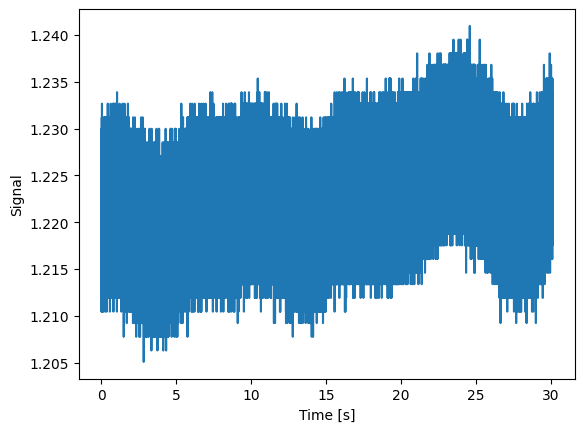

In [3]:
# readFile reads the tdms file and spits out a 1D array with the data.
tSer_Gap = tdmsLib.readFile(path_GapData, fName_preamble, num, grName)
# Display the time series
tdmsLib.dispTimeTrace(tSer_Gap)

In [7]:
path_Christmas = Path.cwd() / "ExampleData" / "StableChristmasData_Sergii" 
fName_preamble = "gap-tween-100nm-np-in gap-trapping-2V"
num_strt = 9
num_end = 11
grName = "_scattering_analog_input_"

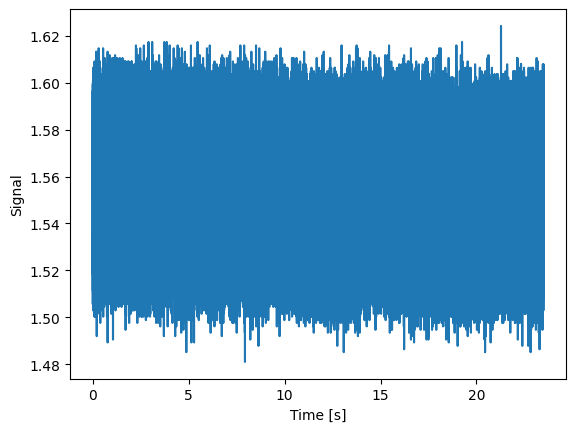

In [8]:
tSer_Stable = tdmsLib.readConsecFiles(path_Christmas, fName_preamble, grName, num_strt, num_end)
# Display the time series
tdmsLib.dispTimeTrace(tSer_Stable)

In [9]:
# An element of the blockSizes array gives the number of data points that will be in each chunk of the "blocked" array.
blockSizes = np.array([1,2,5,10,20,50,100,200,500,1e3,2e3,5e3, 1e4,2e4,5e4,1e5,2e5])
#varArr stores the variance of each array after it's been "blocked" into the appropriate block sizes.
varArr = np.zeros(len(blockSizes))
varArr_delta = np.zeros(len(blockSizes))
varAllanArr = np.zeros(len(blockSizes))
varAllanArr_delta = np.zeros(len(blockSizes))
# varArr, varArr_delta are filled in.
for i in range(len(blockSizes)):
    scatBlocked, remain = tdmsLib.blockData_ave(blockSizes[i], tSer_Stable)
    varAllanArr[i], varAllanArr_delta[i] = tdmsLib.compAllanVar(scatBlocked)

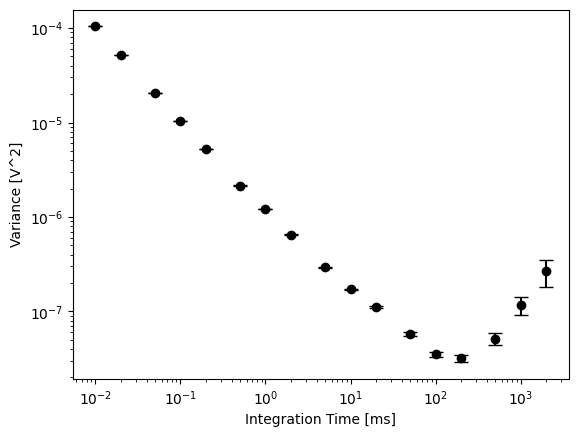

In [10]:
# Graphing stuff :)
fig, ax = plt.subplots()
ax.errorbar(blockSizes*(tSer_Stable.dT/1e-3), varAllanArr, yerr=varAllanArr_delta, fmt="o", color="black", capsize=5)
ax.set_ylabel("Variance [V^2]")
ax.set_xlabel("Integration Time [ms]")
ax.set_yscale('log')
ax.set_xscale('log')
plt.show()

In [11]:
def allanVarFunc(tau, s, d):
    return s*(tau**(-1))+d*(tau**2)

[1.04243051e-06 1.43081308e-13]


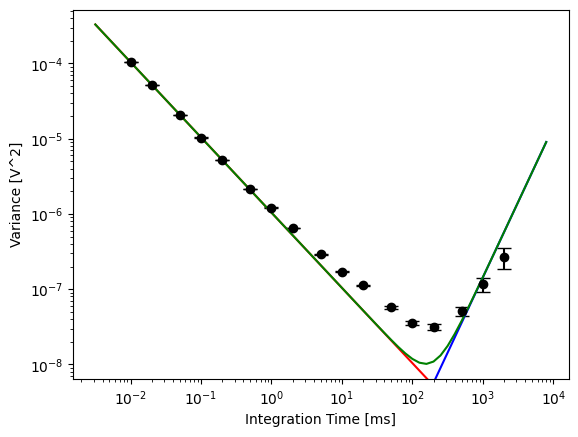

In [12]:
from scipy.optimize import curve_fit

popt, pcov = curve_fit(allanVarFunc, blockSizes*(tSer_Stable.dT/1e-3), varAllanArr, p0=[3e-8,1e-11], sigma=varAllanArr_delta, absolute_sigma=True)
print(popt)

xPnts = 10**(np.arange(-2.5,4,0.1))
#yPnts = np.zeros(len(xPnts)) + 1E-7
yPnts_shot = popt[0]*(xPnts**(-1))
yPnts_drift = popt[1]*(xPnts**(2))
yPnts_fit = allanVarFunc(xPnts, popt[0], popt[1])

fig, ax = plt.subplots()
ax.errorbar(blockSizes*1e-2, varAllanArr, yerr=varAllanArr_delta, fmt="o", color="black", capsize=5)
ax.plot(xPnts,yPnts_shot, color="red")
ax.plot(xPnts,yPnts_drift, color="blue")
ax.plot(xPnts,yPnts_fit, color="green")
ax.set_ylabel("Variance [V^2]")
ax.set_xlabel("Integration Time [ms]")
ax.set_yscale('log')
ax.set_xscale('log')
ax.set_ylim(np.min(varAllanArr)/5,np.max(varAllanArr)*5)
plt.show()

In [13]:
# Saving the results in a csv to graph later in whatever graphing software you like.
np.savetxt('AllanVar.csv', np.array(list(zip(blockSizes*1e-2, varArr, varArr_delta))), delimiter=',', header="Integration Time [ms] | Allan Var. | Allan Var. Delta")